# Klasifikasi Kelangsungan Hidup Karakter Game of Thrones
---

## 1. Business Understading

### 1.1 Latar Belakang, Masalah, dan Solusi
1. **Latar Belakang**: ebuah platform analisis media dan penerbitan buku novel ingin membangun sistem kecerdasan buatan berbasis Machine Learning untuk memprediksi tingkat kelangsungan hidup (survival rate) atau potensi kematian karakter dalam serial novel populer Game of Thrones / A Song of Ice and Fire secara otomatis.
2. **Masalah**: Platform tersebut masih menganalisis dan memprediksi tingkat kelangsungan hidup (*survival rate*) secara manual yang memakan waktu.
3. **Solusi**: Membangun model *machine learning* dengan algoritma **Random Forest** dengna memanfaatkan atribut demografis, latar belakang klan/hosue.

### 1.2 Deskripsi Kolom Dataset `HW2.csv`
| **Nama Kolom** | **Tipe Data** | **Keterangan** |
| :-- | :-- | :-- |
| `S.No` | `int64` | Nomor urut identifikasi data |
| `plod` | `float64` | Nilai estimasi probabilitas kematian berdasarkan analisis statistik (Probability of Life or Death). |
| `name` | `str` | Nama lengkap karakter. |
| `title` | `str` | Gelar/jabatan karakter (misal: Lord, Ser, Queen). |
| `gender` | `int64` | Jenis kelamin karakter (Kategori biner: 1 untuk Pria, 0 untuk Wanita). |
| `culture` | `str` | atar belakang kebudayaan/suku asal karakter (misal: Rivermen, Dornish, Northmen). |
| `dateOfBirth` | `float64` | Tahun kelahiran karakter (satuan: Tahun/Era Westeros). |
| `DateoFdeath` | `float64` | Tahun kematian karakter (jika sudah meninggal). |
| `mother` | `str` | Nama ibu dari karakter. |
| `father` | `str` | Nama ayah dari karakter. |
| `heir` | `str` | Nama ahli waris dari karakter. |
| `house` | `str` | Nama klan/keluarga (House) utama (misal: House Stark, House Lannister, House Targaryen). |
| `spouse` | `str` | Nama pasangan/suami/istri dari karakter. |
| `book1` | `int64` | Indikator kemunculan karakter pada Buku 1 (A Game of Thrones) (Kategori biner: 1 muncul, 0 tidak). |
| `book2` | `int64` | Indikator kemunculan karakter pada Buku 2 (A Clash of Kings) (Kategori biner: 1 muncul, 0 tidak). |
| `book3` | `int64` | Indikator kemunculan karakter pada Buku 3 (A Storm of Swords) (Kategori biner: 1 muncul, 0 tidak). |
| `book4` | `int64` | Indikator kemunculan karakter pada Buku 4 (A Feast for Crows) (Kategori biner: 1 muncul, 0 tidak). |
| `book5` | `int64` | Indikator kemunculan karakter pada Buku 5 (A Dance with Dragons) (Kategori biner: 1 muncul, 0 tidak). |
| `isAliveMother` | `float64` | Status kelangsungan hidup ibu karakter (Kategori biner: 1 hidup, 0 meninggal). |
| `isAliveFather` | `float64` | Status kelangsungan hidup ayah karakter (Kategori biner: 1 hidup, 0 meninggal). |
| `isAliveHeir` | `float64` | Status kelangsungan hidup ahli waris (Kategori biner: 1 hidup, 0 meninggal). |
| `isAliveSpouse` | `float64` | Status kelangsungan hidup pasangan (Kategori biner: 1 hidup, 0 meninggal). |
| `isMarried` | `int64` | Status pernikahan karakter (Kategori biner: 1 menikah, 0 tidak). |
| `isNoble` | `int64` | Status kebangsawaan karakter (Kategori biner: 1 bangsawan, 0 rakyat biasa). |
| `age` | `float64` | Usia karakter (satuan: Tahun) |
| `numDeadRelations` | `int64` | Jumlah kerabat/keluarga dekat karakter yang telah meninggal (satuan: Orang). |
| `boolDeadRelations` | `int64` | ndikator apakah karakter memiliki kerabat yang meninggal (Kategori biner: 1 ya, 0 tidak). |
| `isPopular` | `int64` | Indikator apakah karakter merupakan tokoh populer (Kategori biner: 1 ya, 0 tidak). | 
| `popularity` | `float64` | Skor tingkat popularitas karakter dalam cerita (satuan: Skala rasio 0.0 sampai 1.0). |
| `isAlive` | `int64` | Status kelangsungan hidup karakter (0 = Karakter Meninggal, 1 = Karakter Masih Hidup).|

---
## 2. Data Preparation

### 2.1 Import Library

In [54]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load Dataset

In [55]:
df = pd.read_csv('HW2.csv')
df.columns = df.columns.str.strip()

### 2.3 Tampilkan Informasi Data

In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1946 entries, 0 to 1945
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   S.No               1946 non-null   int64  
 1   plod               1946 non-null   float64
 2   name               1946 non-null   str    
 3   title              938 non-null    str    
 4   gender             1946 non-null   int64  
 5   culture            677 non-null    str    
 6   dateOfBirth        433 non-null    float64
 7   DateoFdeath        444 non-null    float64
 8   mother             21 non-null     str    
 9   father             26 non-null     str    
 10  heir               23 non-null     str    
 11  house              1519 non-null   str    
 12  spouse             276 non-null    str    
 13  book1              1946 non-null   int64  
 14  book2              1946 non-null   int64  
 15  book3              1946 non-null   int64  
 16  book4              1946 non-null   

### 2.4 Memeriksa Dimensi Data, Jumlah Data, Missing Value, dan Data Duplikat

In [57]:
print(f'Dimensi Data: {df.shape}')
print(f'Jumlah Data: {df.size}')

print(f'\nJumlah Missing Value: {df.isnull().sum().sum()}')
print(f'\n==== Jumlah Missing Value per Kolom ====\n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'Jumlah Data Duplikat: {df.duplicated().sum()}')

Dimensi Data: (1946, 30)
Jumlah Data: 58380

Jumlah Missing Value: 22108

==== Jumlah Missing Value per Kolom ====
title            1008
culture          1269
dateOfBirth      1513
DateoFdeath      1502
mother           1925
father           1920
heir             1923
house             427
spouse           1670
isAliveMother    1925
isAliveFather    1920
isAliveHeir      1923
isAliveSpouse    1670
age              1513
dtype: int64
Jumlah Data Duplikat: 0


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Tamplkan Deskripsi Data

In [58]:
df.describe()

,S.No,plod,gender,dateOfBirth,DateoFdeath,book1,book2,book3,book4,book5,...,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,boolDeadRelations,isPopular,popularity,isAlive
count,1946.000000,1946.000000,1946.000000,433.000000,444.000000,1946.000000,1946.000000,1946.000000,1946.000000,1946.000000,...,23.000000,276.000000,1946.000000,1946.000000,433.000000,1946.000000,1946.000000,1946.000000,1946.000000,1946.000000
mean,973.500000,0.365530,0.619219,1577.364896,2950.193694,0.198356,0.374615,0.480473,0.591984,0.395170,...,0.652174,0.778986,0.141829,0.460946,-1293.563510,0.305755,0.074512,0.059096,0.089584,0.745632
std,561.906131,0.312637,0.485704,19565.414460,28192.245529,0.398864,0.484148,0.499747,0.491593,0.489013,...,0.486985,0.415684,0.348965,0.498601,19564.340993,1.383910,0.262669,0.235864,0.160568,0.435617
min,1.000000,0.000000,0.000000,-28.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,-298001.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,487.250000,0.101000,0.000000,240.000000,282.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,18.000000,0.000000,0.000000,0.000000,0.013378,0.000000
50%,973.500000,0.264500,1.000000,268.000000,299.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,1.000000,1.000000,0.000000,0.000000,27.000000,0.000000,0.000000,0.000000,0.033445,1.000000
75%,1459.750000,0.608750,1.000000,285.000000,299.000000,0.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,0.000000,1.000000,50.000000,0.000000,0.000000,0.000000,0.086957,1.000000
max,1946.000000,1.000000,1.000000,298299.000000,298299.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,100.000000,15.000000,1.000000,1.000000,1.000000,1.000000


### 3.2 Anallisis Outlier Pada kolom Numerik

In [59]:
numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()

outliers = []

for col in numeric_columns:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        mean = df[col].mean()
        median = df[col].median()
        std = df[col].std()
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        z_score = (df[col] - mean) / std
        outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
        outlier_z_score = df[np.abs(z_score) > 3]
        
        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'standard deviasi': std,
            'min': df[col].min(),
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': df[col].max(),
            'lower bound': lower,
            'upper bound': upper,
            'jumlah outlier (IQR)': outlier_iqr.shape[0],
            'jumlah outlier (Z-Score)': outlier_z_score.shape[0]
        })
        
pd.DataFrame(outliers)

,nama kolom,mean,standard deviasi,min,q1,median,q3,max,lower bound,upper bound,jumlah outlier (IQR),jumlah outlier (Z-Score)
0,S.No,973.500000,561.906131,1.0,487.250000,973.500000,1459.750000,1946.0,-971.500000,2918.500000,0,0
1,plod,0.365530,0.312637,0.0,0.101000,0.264500,0.608750,1.0,-0.660625,1.370375,0,0
2,gender,0.619219,0.485704,0.0,0.000000,1.000000,1.000000,1.0,-1.500000,2.500000,0,0
3,dateOfBirth,1577.364896,19565.414460,-28.0,240.000000,268.000000,285.000000,298299.0,172.500000,352.500000,55,2
4,DateoFdeath,2950.193694,28192.245529,0.0,282.000000,299.000000,299.000000,298299.0,256.500000,324.500000,100,4
5,book1,0.198356,0.398864,0.0,0.000000,0.000000,0.000000,1.0,0.000000,0.000000,386,0
6,book2,0.374615,0.484148,0.0,0.000000,0.000000,1.000000,1.0,-1.500000,2.500000,0,0
7,book3,0.480473,0.499747,0.0,0.000000,0.000000,1.000000,1.0,-1.500000,2.500000,0,0
8,book4,0.591984,0.491593,0.0,0.000000,1.000000,1.000000,1.0,-1.500000,2.500000,0,0
9,book5,0.395170,0.489013,0.0,0.000000,0.000000,1.000000,1.0,-1.500000,2.500000,0,0


### 3.3 VIsualisasi Outlier Dengan Boxplot

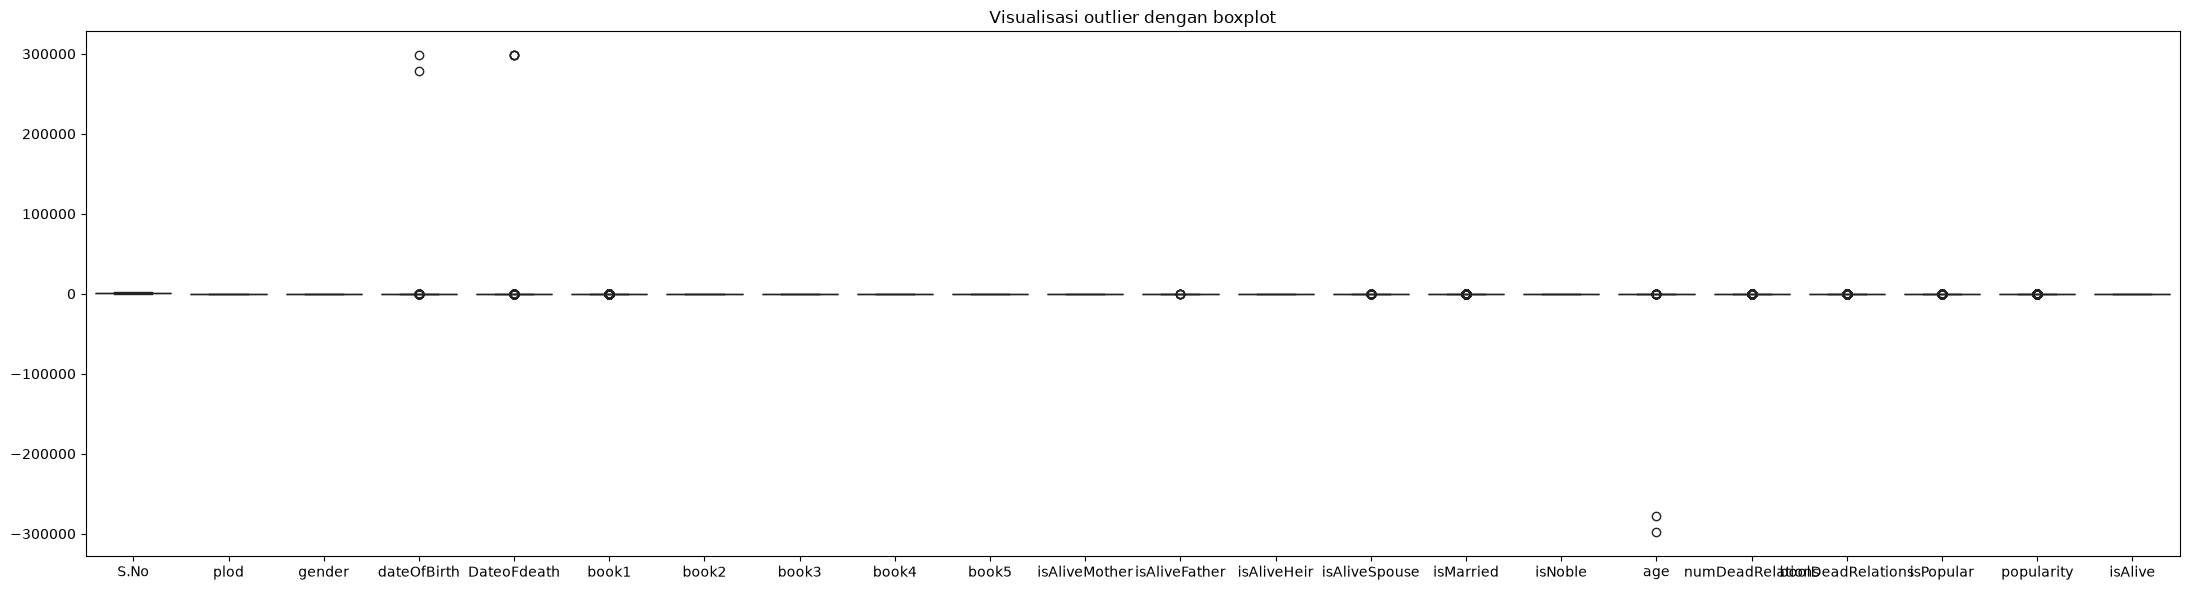

In [60]:
plt.figure(figsize=(22, 6))
sns.boxplot(data=df[numeric_columns], palette='viridis')
plt.title('Visualisasi outlier dengan boxplot')
plt.tight_layout()
plt.show()

### 3.4 Distribusi Variabel Numerik Utama

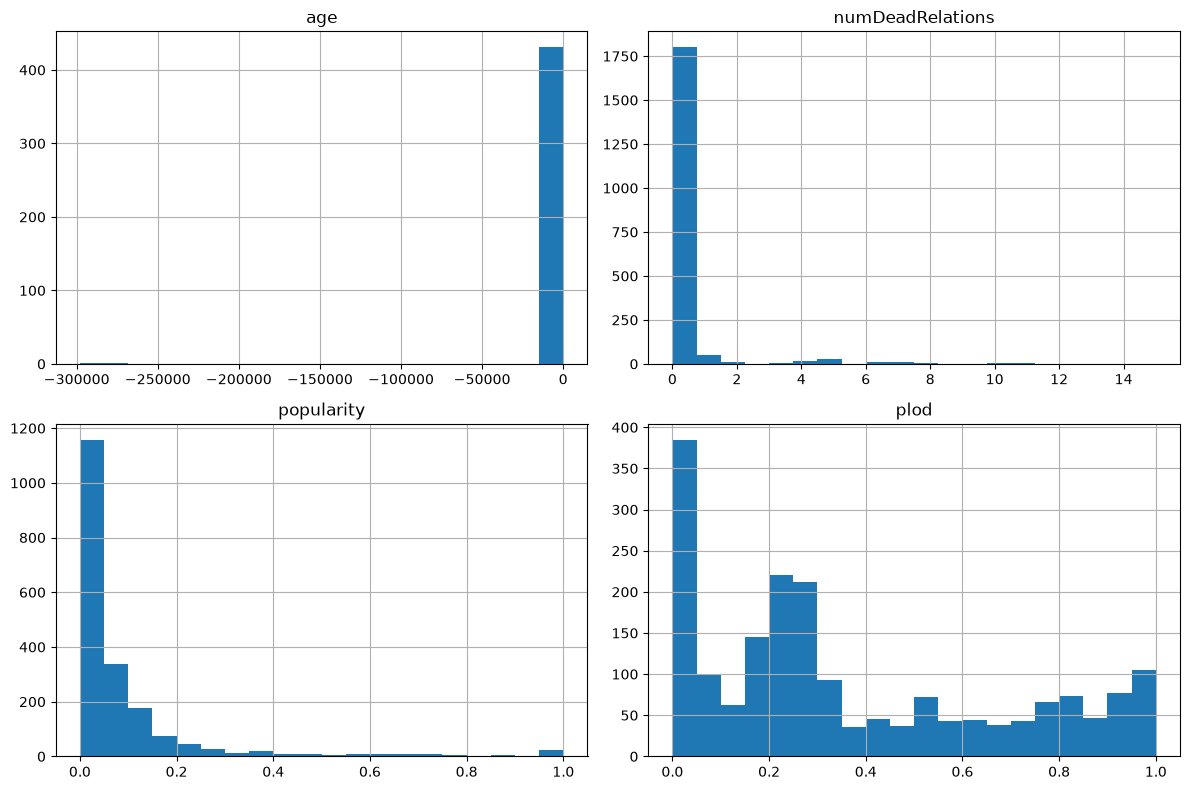

In [61]:
numeric_cols = [ 'age', 'numDeadRelations', 'popularity', 'plod' ]

df[numeric_cols].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

### 3.5 Visualisasi Jumlah Karakter per Buku

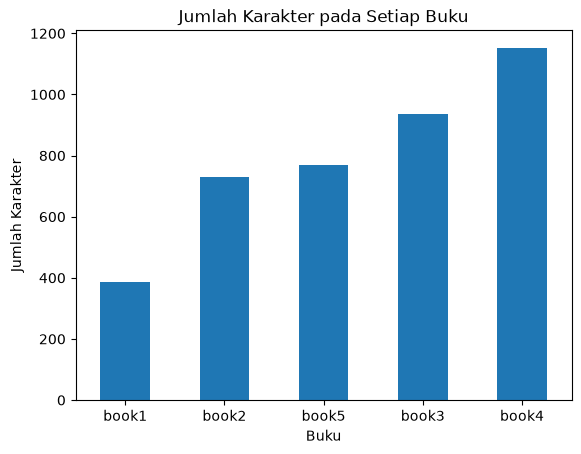

In [62]:
book_cols = ['book1', 'book2', 'book3', 'book4', 'book5']

book_counts = df[book_cols].sum().sort_values()

book_counts.plot(kind='bar')
plt.title('Jumlah Karakter pada Setiap Buku')
plt.xlabel('Buku')
plt.ylabel('Jumlah Karakter')
plt.xticks(rotation=0)
plt.show()

### 3.6 Distribusi Target (`isAlive`)

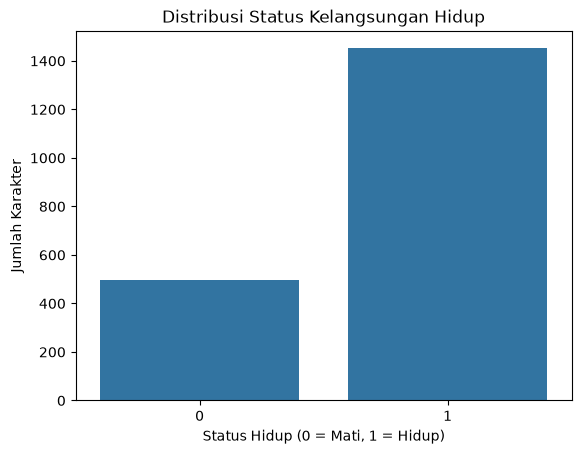

In [63]:
sns.countplot(data=df, x='isAlive')
plt.title('Distribusi Status Kelangsungan Hidup')
plt.xlabel('Status Hidup (0 = Mati, 1 = Hidup)')
plt.ylabel('Jumlah Karakter')
plt.show()

### 3.7 Analisis Korelasi Pada Kolom Numerik Dengan Heatmap

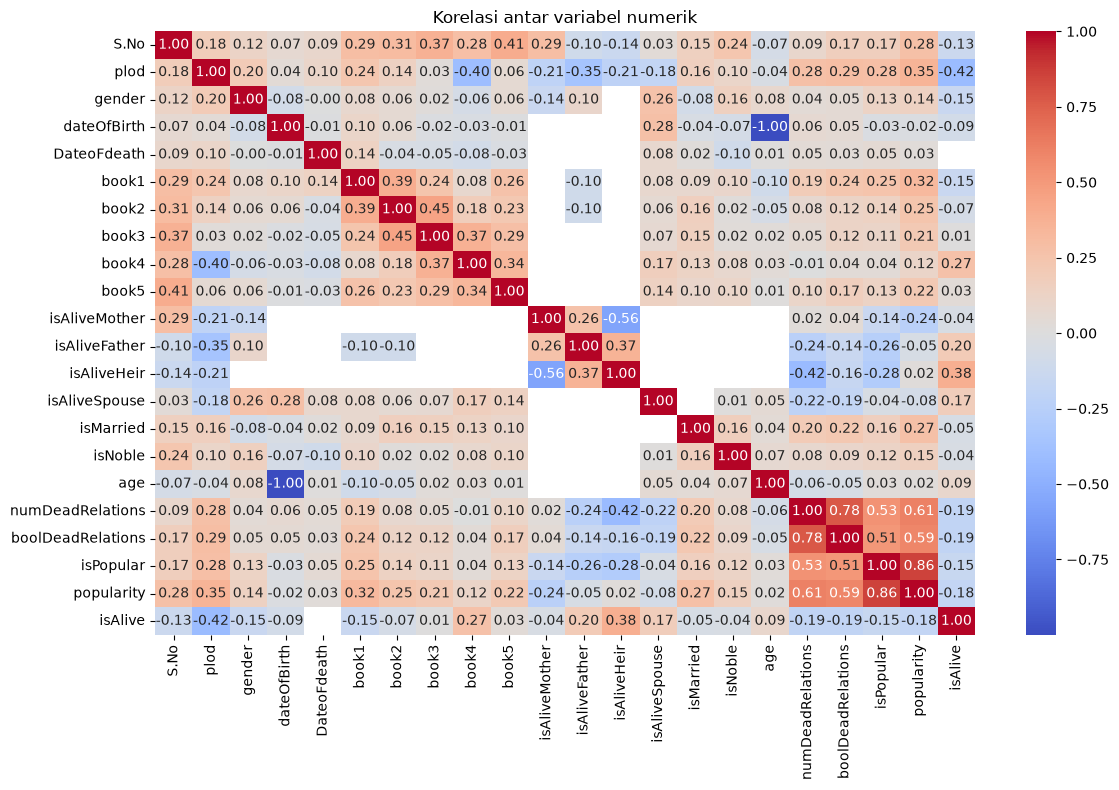

In [64]:
var_list = numeric_columns

plt.figure(figsize=(12, 8))
sns.heatmap(df[var_list].corr(method='pearson'), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi antar variabel numerik')
plt.tight_layout()
plt.show()

In [67]:
def to_binary(value):
    return 1 if value == "Ya" else 0

def predict_isAlive():
    try:
        gender = entryGender.get()
        if gender == "Laki-Laki":
            gender = 1
        elif gender == "Perempuan":
            gender = 0
        else:
            raise ValueError("Gender harus 'Laki-laki' atau 'Perempuan'")
        
        
        age = float(entryAge.get())
        
        book1 = to_binary(entryBook1.get())
        book2 = to_binary(entryBook2.get())
        book3 = to_binary(entryBook3.get())
        book4 = to_binary(entryBook4.get())
        book5 = to_binary(entryBook5.get())
        
        is_married = to_binary(entryIsMarried.get())
        is_noble = to_binary(entryIsNoble.get())
        bool_dead_relations = to_binary(entryBoolDeadRelations.get())
        
        num_dead_relations = int(entryNumDeadRelations.get())
        is_popular = to_binary(entryIsPopular.get())
        popularity = float(entryPopularity.get())
        plod = float(entryPlod.get())
        
        if age < 0:
            raise ValueError("umur tidak boleh negatif")
        
        if num_dead_relations < 0:
            raise ValueError("jumlah hubungan mati tidak boleh negatif")
        
        if not 0 <= popularity <= 1:
            raise ValueError("popularity harus antara 0 dan 1")
        
        if not 0 <= plod <= 1:
            raise ValueError("plod harus antara 0 dan 1")
        
        if bool_dead_relations == 0 and num_dead_relations > 0:
            raise ValueError("BoolDeadRelations haruss 'Ya' jika jumlah kerabat meninggal lebih dari 0")
        
        if bool_dead_relations == 1 and num_dead_relations == 0:
            raise ValueError("BoolDeadRelations tidak boleh 'Ya' jika jumlah kerabat meninggal adalah 0")
        
        feature_cols = [
            'gender', 'age', 'book1', 'book2', 'book3', 'book4', 'book5',
            'isMarried', 'isNoble', 'boolDeadRelations', 'numDeadRelations',
            'isPopular', 'popularity', 'plod'
        ]
        
        input_values = [[
            gender, age, book1, book2, book3, book4, book5,
            is_married, is_noble, bool_dead_relations, num_dead_relations,
            is_popular, popularity, plod
        ]]
        
        input_data = pd.DataFrame(input_values, columns=feature_cols)
        
        score = (
            (age * 0.01)
            + (book1 + book2 + book3 + book4 + book5) * 0.10
            + is_married * 0.20
            + is_noble * 0.20
            + is_popular * 0.20
            + popularity * 0.50
            + plod * 0.50
            - num_dead_relations * 0.10
        )
        
        prediction = np.where(score >= 1.0, 1, 0)[()]
        
        if prediction == 1:
            lblPredictionResult.configure(
                text="Prediksi: Karakter ini kemungkinan akan hidup.",
                text_color="green"
            )
        else:
            lblPredictionResult.configure(
                text="Prediksi: Karakter ini kemungkinan akan mati.",
                text_color="red"
            )
    except ValueError as error:
            lblPredictionResult.configure(
                text=f"Error: {error}",
                text_color="red"
            )

---
## 7. GUI

In [68]:
from customtkinter import *

app = CTk()
app.title("Klasifikasi Kelangsungan Hidup Karakter Game of Thrones")

lebar = 600
tinggi = 700
screen_width = app.winfo_screenwidth()
screen_height = app.winfo_screenheight()
x = int((screen_width / 2) - (lebar / 2))
y = int((screen_height / 2) - (tinggi / 2))
app.geometry(f"{lebar}x{tinggi}+{x}+{y}")
set_appearance_mode("light")

MainFrame = CTkScrollableFrame(app, fg_color="#fff", corner_radius=12)
MainFrame.pack(padx=20, pady=20, fill="both", expand=True)

lblGender = CTkLabel(MainFrame, text="Jenis Kelamin", font=("Arial", 16), justify="left")
lblGender.pack(pady=5, padx=10, anchor="w")
entryGender = CTkSegmentedButton(MainFrame, values=["Laki-Laki", "Perempuan"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryGender.pack(pady=(0, 5), padx=10, fill="x")

lblAge = CTkLabel(MainFrame, text="Usia", font=("Arial", 16), justify="left")
lblAge.pack(pady=5, padx=10, anchor="w")
entryAge = CTkEntry(MainFrame, placeholder_text="Masukkan usia karakter", font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryAge.pack(pady=(0, 5), padx=10, fill="x")

lblBook1 = CTkLabel(MainFrame, text="Apakah karakter muncul di buku A Game of Thrones?", font=("Arial", 16))
lblBook1.pack(pady=5, padx=10, anchor="w")
entryBook1 = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryBook1.pack(pady=(0, 10), padx=10, fill="x")

lblBook2 = CTkLabel(MainFrame, text="Apakah karakter muncul di buku A Clash of Kings?", font=("Arial", 16))
lblBook2.pack(pady=5, padx=10, anchor="w")
entryBook2 = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryBook2.pack(pady=(0, 10), padx=10, fill="x")

lblBook3 = CTkLabel(MainFrame, text="Apakah karakter muncul di buku A Storm of Swords?", font=("Arial", 16))
lblBook3.pack(pady=5, padx=10, anchor="w")
entryBook3 = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryBook3.pack(pady=(0, 10), padx=10, fill="x")

lblBook4 = CTkLabel(MainFrame, text="Apakah karakter muncul di buku A Feast for Crows?", font=("Arial", 16))
lblBook4.pack(pady=5, padx=10, anchor="w")
entryBook4 = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryBook4.pack(pady=(0, 10), padx=10, fill="x")

lblBook5 = CTkLabel(MainFrame, text="Apakah karakter muncul di buku A Dance with Dragons?", font=("Arial", 16))
lblBook5.pack(pady=5, padx=10, anchor="w")
entryBook5 = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryBook5.pack(pady=(0, 10), padx=10, fill="x")

lblIsMarried = CTkLabel(MainFrame, text="Apakah karakter menikah?", font=("Arial", 16))
lblIsMarried.pack(pady=5, padx=10, anchor="w")
entryIsMarried = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryIsMarried.pack(pady=(0, 10), padx=10, fill="x")

lblIsNoble = CTkLabel(MainFrame, text="Apakah karakter bangsawan?", font=("Arial", 16))
lblIsNoble.pack(pady=5, padx=10, anchor="w")
entryIsNoble = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryIsNoble.pack(pady=(0, 10), padx=10, fill="x")

lblBoolDeadRelations = CTkLabel(MainFrame, text="Apakah karakter memiliki kerabat yang mati?", font=("Arial", 16))
lblBoolDeadRelations.pack(pady=5, padx=10, anchor="w")
entryBoolDeadRelations = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryBoolDeadRelations.pack(pady=(0, 10), padx=10, fill="x")

lblNumDeadRelations = CTkLabel(MainFrame, text="Jumlah kerabat yang mati", font=("Arial", 16), justify="left")
lblNumDeadRelations.pack(pady=5, padx=10, anchor="w")
entryNumDeadRelations = CTkEntry(MainFrame, placeholder_text="Masukkan jumlah kerabat yang mati", font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryNumDeadRelations.pack(pady=(0, 5), padx=10, fill="x")

lblIsPopular = CTkLabel(MainFrame, text="Apakah karakter populer?", font=("Arial", 16), justify="left")
lblIsPopular.pack(pady=5, padx=10, anchor="w")
entryIsPopular = CTkSegmentedButton(MainFrame, values=["Ya", "Tidak"], font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryIsPopular.pack(pady=(0, 10), padx=10, fill="x")

lblPopularity = CTkLabel(MainFrame, text="Popularitas karakter", font=("Arial", 16), justify="left")
lblPopularity.pack(pady=5, padx=10, anchor="w")
entryPopularity = CTkEntry(MainFrame, placeholder_text="Masukkan popularitas karakter", font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryPopularity.pack(pady=(0, 5), padx=10, fill="x")

lblPlod = CTkLabel(MainFrame, text="Plod karakter", font=("Arial", 16), justify="left")
lblPlod.pack(pady=5, padx=10, anchor="w")
entryPlod = CTkEntry(MainFrame, placeholder_text="Masukkan plod karakter", font=("Arial", 16), fg_color="#fff", corner_radius=8)
entryPlod.pack(pady=(0, 5), padx=10, fill="x")

btnPredict = CTkButton(app, text="Prediksi Kelangsungan Hidup", font=("Arial", 16), corner_radius=8, command=predict_isAlive)
btnPredict.pack(pady=10, padx=20, fill="x")

lblPredictionResult = CTkLabel(app, text="Hasil Prediksi: -", font=("Arial", 16), justify="center")
lblPredictionResult.pack(pady=10, padx=20, fill="x")

app.mainloop()

---

## 8. Conclusion

### 8.1 Kesimpulan Analisis dan Pemodelan

Berdasarkan seluruh rangkaian analisis data, pemrosesan awal, pembangunan model, hingga evaluasi yang telah dijalankan, diperoleh beberapa kesimpulan utama sebagai berikut:

1. Dataset awal memiliki total **1946 baris dan 30 kolom** serta ditemukan adanya (*missing value*) dengan total **22108 Missing Value** yang tersebar pada beberapa kolom. Dan tidak ditemukan adanya *data duplikat* pada keseluruhan dataset ini. [Lihat Pemeriksaan Data](#23-tampilkan-informasi-data)